# XGBoost — Oil production forecasting 

1. Load and preprocess data
2. Build lag features
3. Fit the XGBoost model
4. Evaluate on the test set

1. Load and preprocess data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42
np.random.seed(SEED)

In [2]:
# Read data and keep well NO 15/9-F-12 H (selected in EDA)
data_path = Path("../data/Raw_prod_data.xlsx")
df = pd.read_excel(data_path)
df = df[df["WELL_BORE_CODE"] == "NO 15/9-F-12 H"].sort_values("DATEPRD").reset_index(drop=True)

features = ['ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE', 'AVG_DOWNHOLE_TEMPERATURE', 'AVG_DP_TUBING',
            'AVG_ANNULUS_PRESS', 'AVG_CHOKE_SIZE_P', 'AVG_WHP_P', 'AVG_WHT_P', 'DP_CHOKE_SIZE']
target = 'BORE_OIL_VOL'

df = df[['DATEPRD'] + features + [target]].drop_duplicates().reset_index(drop=True)
print("Dimension: ", df.shape)
print(df.isna().sum())

Dimension:  (3056, 11)
DATEPRD                      0
ON_STREAM_HRS                0
AVG_DOWNHOLE_PRESSURE        6
AVG_DOWNHOLE_TEMPERATURE     6
AVG_DP_TUBING                6
AVG_ANNULUS_PRESS           13
AVG_CHOKE_SIZE_P            44
AVG_WHP_P                    0
AVG_WHT_P                    0
DP_CHOKE_SIZE                0
BORE_OIL_VOL                 0
dtype: int64


In [3]:
# Handle missing values: linear interpolation over time, then fill the edges
df[features] = df[features].interpolate(method="linear").ffill().bfill()
print("Remaining missing values:", df.isna().sum().sum())

Remaining missing values: 0


2. Build lag features

In [4]:
# Each sample uses features and oil volume from previous days to predict the next day's oil volume
# (same information as the CNN's sliding window, flattened into tabular lag columns)
LAGS = [1, 2, 3, 7, 14, 30]
cols = features + [target]

lagged = {}
for lag in LAGS:
    for c in cols:
        lagged[f"{c}_lag{lag}"] = df[c].shift(lag)
# Rolling statistics of past oil volume (shifted so the current day is never included)
for w in [7, 30]:
    lagged[f"{target}_mean{w}"] = df[target].shift(1).rolling(w).mean()
    lagged[f"{target}_std{w}"] = df[target].shift(1).rolling(w).std()

X_all = pd.DataFrame(lagged)
y_all = df[target]

# Drop the first rows that do not have a full history
valid = X_all.notna().all(axis=1)
X_all, y_all = X_all[valid], y_all[valid]
t_idx = X_all.index.to_numpy()
print("Feature matrix:", X_all.shape)

Feature matrix: (3026, 64)


In [5]:
# Chronological split: 70% train, 15% validation, 15% test (same boundaries as the CNN)
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_mask = t_idx < train_end
val_mask = (t_idx >= train_end) & (t_idx < val_end)
test_mask = t_idx >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)
print("Mean oil volume  train: %.0f  val: %.0f  test: %.0f" % (y_train.mean(), y_val.mean(), y_test.mean()))

Train: (2109, 64) Val: (458, 64) Test: (459, 64)
Mean oil volume  train: 1993  val: 337  test: 298


Production declines strongly over time, so the validation and test periods sit far below most of the training data.
Trees cannot extrapolate beyond the target values seen in training, so instead of the volume itself the model predicts
the **change from the previous day**; the forecast is then `yesterday's volume + predicted change`.

In [6]:
# Target = daily change in oil volume
last_vol = X_all[f"{target}_lag1"]
d_train = y_train - last_vol[train_mask]
d_val = y_val - last_vol[val_mask]

3. Fit the XGBoost model

In [7]:
# Tree models do not need feature scaling; the validation set drives early stopping
model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=1.0,
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=50,
    random_state=SEED,
)

model.fit(X_train, d_train, eval_set=[(X_train, d_train), (X_val, d_val)], verbose=100)
print("Best iteration:", model.best_iteration)

[0]	validation_0-rmse:532.02515	validation_1-rmse:99.79839
[50]	validation_0-rmse:374.21923	validation_1-rmse:125.12494
Best iteration: 0


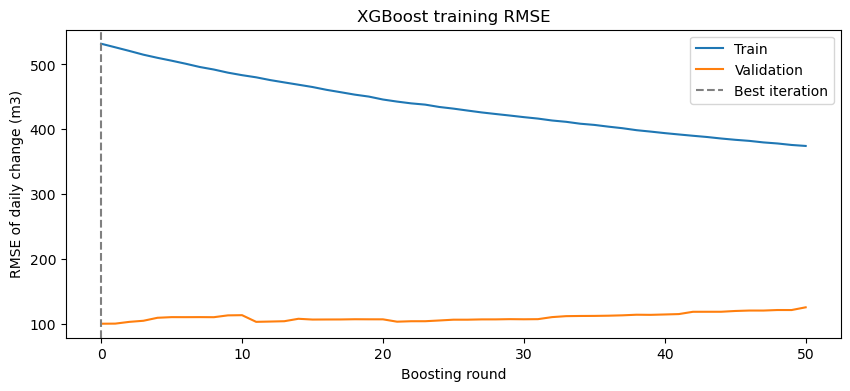

In [8]:
# Learning curves
results = model.evals_result()
plt.figure(figsize=(10, 4))
plt.plot(results["validation_0"]["rmse"], label="Train")
plt.plot(results["validation_1"]["rmse"], label="Validation")
plt.axvline(model.best_iteration, color="gray", linestyle="--", label="Best iteration")
plt.title("XGBoost training RMSE")
plt.xlabel("Boosting round")
plt.ylabel("RMSE of daily change (m3)")
plt.legend()
plt.show()

4. Evaluate on the test set

In [9]:
def report(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<22} RMSE: {rmse:8.2f}  MAE: {mae:8.2f}  R2: {r2:.3f}")

def evaluate(X, y, name):
    y_true = y.to_numpy()
    # Forecast = yesterday's volume + predicted change; production cannot be negative
    y_pred = np.clip(X[f"{target}_lag1"].to_numpy() + model.predict(X), 0, None)
    report(y_true, y_pred, name)
    return y_true, y_pred

evaluate(X_train, y_train, "Train")
evaluate(X_val, y_val, "Validation")
y_true_test, y_pred_test = evaluate(X_test, y_test, "Test")

# Persistence baseline (tomorrow = today): any useful model should beat this
print()
report(y_val, X_val[f"{target}_lag1"], "Persistence validation")
report(y_test, X_test[f"{target}_lag1"], "Persistence test")

Train                  RMSE:   532.02  MAE:   200.36  R2: 0.909
Validation             RMSE:    99.80  MAE:    31.60  R2: 0.871
Test                   RMSE:    39.36  MAE:    16.71  R2: 0.947

Persistence validation RMSE:    99.81  MAE:    30.40  R2: 0.871
Persistence test       RMSE:    37.78  MAE:    12.04  R2: 0.951


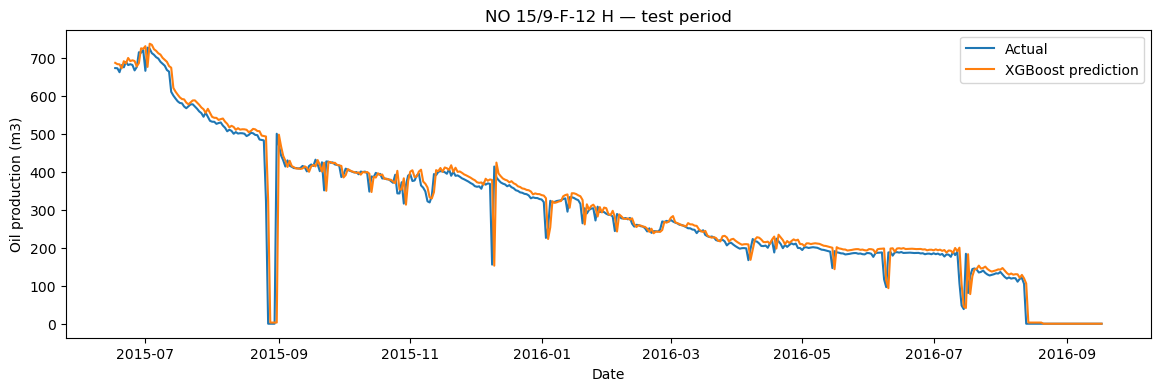

In [10]:
# Actual vs predicted on the test period
test_dates = df["DATEPRD"].iloc[t_idx[test_mask]]

plt.figure(figsize=(14, 4))
plt.plot(test_dates, y_true_test, label="Actual")
plt.plot(test_dates, y_pred_test, label="XGBoost prediction")
plt.title("NO 15/9-F-12 H — test period")
plt.xlabel("Date")
plt.ylabel("Oil production (m3)")
plt.legend()
plt.show()

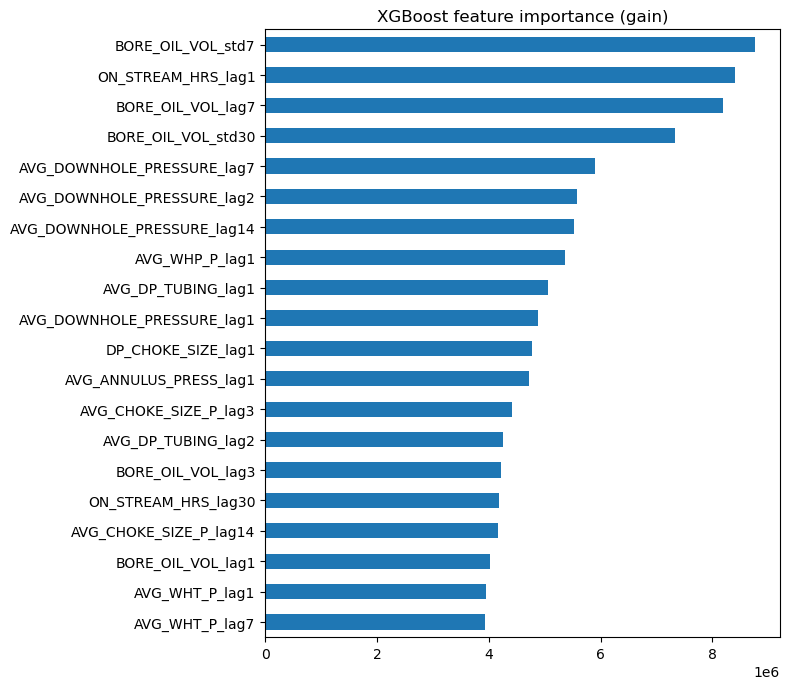

In [11]:
# Top 20 most important features (gain)
importance = pd.Series(model.get_booster().get_score(importance_type="gain")).sort_values()
importance.tail(20).plot(kind="barh", figsize=(8, 7), title="XGBoost feature importance (gain)")
plt.tight_layout()
plt.show()